In [4]:
import pandas as pd

In [17]:
#import kagglehub
# Download latest version
#path = kagglehub.dataset_download("nabeelqureshitiii/student-performance-dataset")
#print("Path to dataset files:", path)

In [18]:
df = pd.read_csv("/Users/berukchimi/.cache/kagglehub/datasets/nabeelqureshitiii/student-performance-dataset/versions/1/student_performance.csv")
df

,student_id,weekly_self_study_hours,attendance_percentage,class_participation,total_score,grade
0,1,18.5,95.6,3.8,97.9,A
1,2,14.0,80.0,2.5,83.9,B
2,3,19.5,86.3,5.3,100.0,A
3,4,25.7,70.2,7.0,100.0,A
4,5,13.4,81.9,6.9,92.0,A
...,...,...,...,...,...,...
999995,999996,18.0,95.5,4.8,100.0,A
999996,999997,15.7,82.7,6.7,88.3,A
999997,999998,14.2,85.1,5.8,87.9,A
999998,999999,25.3,90.0,5.3,100.0,A


In [19]:
#def clean_data(df):
#    df = df.drop_duplicates()
#    cols = 

In [50]:
def transform_data(df):
    df["niveau"] = pd.cut(df.total_score,
                         bins = [0,49,79,100],
                         labels = ["Needs Improvement",
                                   "Good", "Excellent"])
    df["att_group"] = pd.cut(df.attendance_percentage,
                        bins = [0, 75, 90, 100],
                        labels = ["Low", "Mid", "Excellent"])
    return df 

In [51]:
def analyse_data(df):
    summary = df.groupby("att_group").agg(
                                            avg_study = ("weekly_self_study_hours", "mean"),
                                            avg_score = ("total_score", "mean"),
                                            students = ("student_id", "count"))
    corr = df.corr(numeric_only = True)
    return summary , corr
        

In [52]:
def load_result(df, summary):
    summary.to_csv ("analysis_results")

In [54]:
df = transform_data(df)
summary, corr = analyse_data(df)
load_result(df, summary)

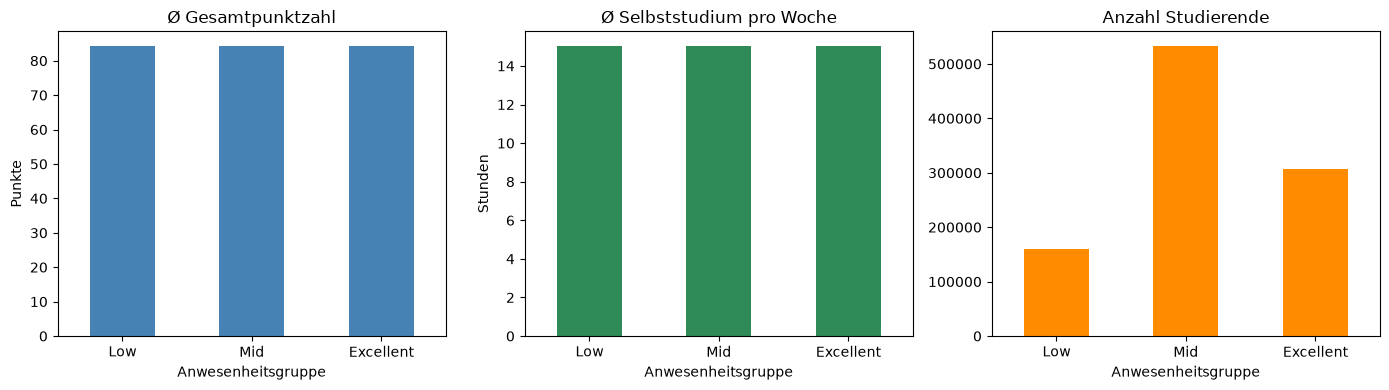

In [55]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

summary["avg_score"].plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Ø Gesamtpunktzahl")
axes[0].set_ylabel("Punkte")

summary["avg_study"].plot(kind="bar", ax=axes[1], color="seagreen")
axes[1].set_title("Ø Selbststudium pro Woche")
axes[1].set_ylabel("Stunden")

summary["students"].plot(kind="bar", ax=axes[2], color="darkorange")
axes[2].set_title("Anzahl Studierende")

for ax in axes:
    ax.set_xlabel("Anwesenheitsgruppe")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig("summary_plot.png", dpi=300)
plt.show()

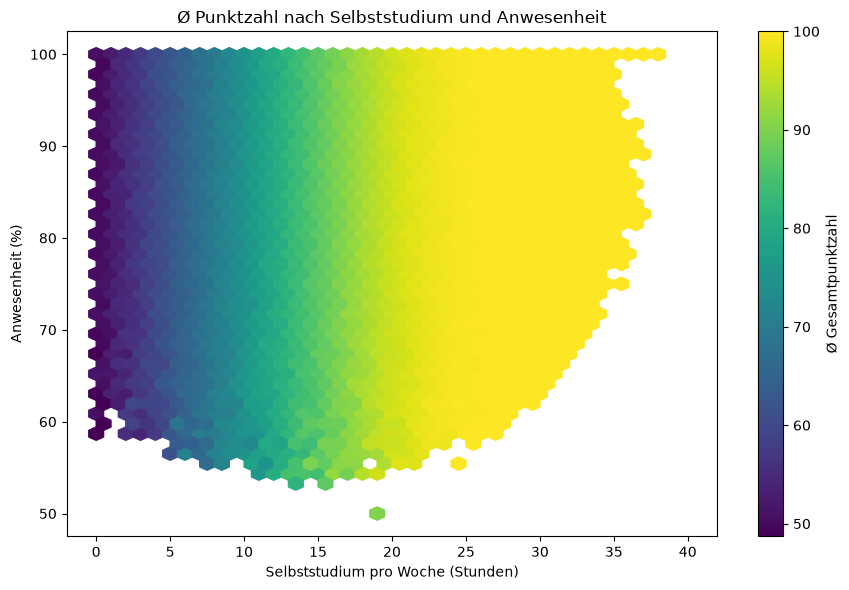

AttributeError: module 'matplotlib.pyplot' has no attribute 'save'

In [63]:
import numpy as np
fig, ax = plt.subplots(figsize=(9, 6))
hb = ax.hexbin(
    df["weekly_self_study_hours"],
    df["attendance_percentage"],
    C=df["total_score"],
    reduce_C_function=np.mean,
    gridsize=40,
    cmap="viridis",
    mincnt=20,
)
cbar = plt.colorbar(hb, ax=ax)
cbar.set_label("Ø Gesamtpunktzahl")

ax.set_xlabel("Selbststudium pro Woche (Stunden)")
ax.set_ylabel("Anwesenheit (%)")
ax.set_title("Ø Punktzahl nach Selbststudium und Anwesenheit")

plt.tight_layout()
plt.savefig("hexbin_3_variablen.png", dpi=300)
plt.show()